In [1]:
from pathlib import Path
from collections import Counter
import csv
import sys

# Define input paths.
import os

# Locate the shared project folder from the notebook working directory.
_start = Path.cwd().resolve()
_override = os.environ.get("GUILLIAMS_PROJECT_DIR")
if _override:
    _project_root = Path(_override).expanduser().resolve()
else:
    _project_root = next(
        (p for p in (_start, *_start.parents)
         if (p / "guilliams_metadata").is_dir()),
        None,
    )
    if _project_root is None:
        raise FileNotFoundError(
            "Keep guilliams_metadata beside the repository, "
            "or set GUILLIAMS_PROJECT_DIR."
        )
PROJECT_DIR = Path(os.path.relpath(_project_root, _start))
ARCHIVE_PATH = PROJECT_DIR / "GSE192742_RAW.tar"
MANIFEST_PATH = (
    PROJECT_DIR / "guilliams_metadata" / "human_sample_review.csv"
)

# Check that both inputs exist.
for path in (ARCHIVE_PATH, MANIFEST_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Missing input: {path}")

# Load the reviewed sample metadata.
with MANIFEST_PATH.open(encoding="utf-8", newline="") as handle:
    reader = csv.DictReader(handle)
    required_columns = {"accession", "donor", "condition", "assay_group"}
    missing_columns = required_columns - set(reader.fieldnames or [])

    if missing_columns:
        raise ValueError(f"Missing manifest columns: {missing_columns}")

    all_samples = list(reader)

# Start with the labeled human single-cell subset.
# Other samples remain in the original manifest.
selected_samples = [
    row for row in all_samples
    if row["assay_group"] == "single_cell"
    and row["condition"] in {"healthy", "disease"}
]

accessions = [row["accession"] for row in selected_samples]

if not selected_samples:
    raise ValueError("No samples matched the selection criteria.")

if len(accessions) != len(set(accessions)):
    raise ValueError("Duplicate sample accessions in the selected manifest.")

print("Python version:", sys.version.split()[0])
print("Archive:", ARCHIVE_PATH)
print("Manifest:", MANIFEST_PATH)
print("Selected samples:", len(selected_samples))
print(
    "Samples by condition:",
    dict(Counter(row["condition"] for row in selected_samples)),
)

for condition in ("healthy", "disease"):
    donors = sorted({
        row["donor"]
        for row in selected_samples
        if row["condition"] == condition
    })
    print(f"{condition}: {len(donors)} donors — {', '.join(donors)}")

Python executable: liver-cell-map/.venv/bin/python
Archive: GSE192742_RAW.tar
Manifest: guilliams_metadata/human_sample_review.csv
Selected samples: 20
Samples by condition: {'disease': 5, 'healthy': 15}
healthy: 9 donors — H06, H07, H10, H13, H16, H18, H22, H23, H25
disease: 3 donors — H04, H11, H21


In [2]:
import tarfile
import numpy as np
import pandas as pd
import h5py

# Match each selected sample to exactly one matrix file.
matrix_index = {}

with tarfile.open(ARCHIVE_PATH, "r") as archive:
    members = [
        member
        for member in archive.getmembers()
        if member.isfile()
        and "filtered_feature_bc_matrix" in member.name
        and member.name.endswith((".h5", ".txt.gz"))
    ]

    for sample in selected_samples:
        accession = sample["accession"]
        matches = [
            member for member in members
            if Path(member.name).name.split("_")[0] == accession
        ]

        if len(matches) != 1:
            raise ValueError(
                f"{accession}: expected one matrix, found {len(matches)}"
            )

        matrix_index[accession] = matches[0].name

sample_table = pd.DataFrame(selected_samples)
sample_table["matrix_file"] = sample_table["accession"].map(matrix_index)
sample_table["format"] = sample_table["matrix_file"].map(
    lambda name: "h5" if name.endswith(".h5") else "txt.gz"
)

print("Matched samples:", len(matrix_index))
print("Matrix formats:", sample_table["format"].value_counts().to_dict())

display(
    sample_table[
        ["accession", "donor", "condition", "format", "matrix_file"]
    ]
)

Matched samples: 20
Matrix formats: {'h5': 14, 'txt.gz': 6}


,accession,donor,condition,format,matrix_file
0,GSM5764358,H04,disease,h5,GSM5764358_filtered_feature_bc_matrix_CS37.h5
1,GSM5764361,H04,disease,h5,GSM5764361_filtered_feature_bc_matrix_CS38.h5
2,GSM5764363,H06,healthy,h5,GSM5764363_filtered_feature_bc_matrix_CS41.h5
3,GSM5764366,H06,healthy,h5,GSM5764366_filtered_feature_bc_matrix_CS42.h5
4,GSM5764368,H06,healthy,txt.gz,GSM5764368_filtered_feature_bc_matrix_CS43.txt.gz
5,GSM5764370,H06,healthy,txt.gz,GSM5764370_filtered_feature_bc_matrix_CS44.txt.gz
6,GSM5764373,H07,healthy,h5,GSM5764373_filtered_feature_bc_matrix_CS46.h5
7,GSM5764375,H10,healthy,h5,GSM5764375_filtered_feature_bc_matrix_CS71.h5
8,GSM5764377,H11,disease,txt.gz,GSM5764377_filtered_feature_bc_matrix_CS73.txt.gz
9,GSM5764380,H13,healthy,txt.gz,GSM5764380_filtered_feature_bc_matrix_CS81.txt.gz


In [3]:
%pip install scipy

In [4]:
import io
from scipy import sparse

def read_h5_rna(archive_path, member_name):
    """Read RNA counts as a cells-by-genes sparse matrix."""
    with tarfile.open(archive_path, "r") as archive:
        source = archive.extractfile(member_name)
        if source is None:
            raise ValueError(f"Cannot read {member_name}")

        with source:
            buffer = io.BytesIO(source.read())

    with h5py.File(buffer, "r") as handle:
        matrix = handle["matrix"]
        features = matrix["features"]

        counts = sparse.csc_matrix(
            (
                matrix["data"][:],
                matrix["indices"][:],
                matrix["indptr"][:],
            ),
            shape=tuple(matrix["shape"][:]),
        )
        counts.check_format(full_check=True)

        barcodes = matrix["barcodes"].asstr()[:]
        gene_ids = features["id"].asstr()[:]
        gene_names = features["name"].asstr()[:]
        feature_types = features["feature_type"].asstr()[:]

    if counts.shape != (len(gene_ids), len(barcodes)):
        raise ValueError("Matrix dimensions do not match feature/barcode lengths.")

    values = counts.data
    if (
        not np.isfinite(values).all()
        or (values < 0).any()
        or (values != np.floor(values)).any()
    ):
        raise ValueError("Counts must be finite, nonnegative integers.")

    if len(set(barcodes)) != len(barcodes):
        raise ValueError("Duplicate barcodes within the library.")

    rna_mask = feature_types == "Gene Expression"
    if not rna_mask.any():
        raise ValueError("No Gene Expression features found.")

    # Keep RNA only and transpose to cells × genes.
    rna_counts = counts[rna_mask, :].T.tocsr()
    rna_counts.sum_duplicates()
    rna_counts.eliminate_zeros()

    return {
        "counts": rna_counts,
        "barcodes": barcodes,
        "gene_ids": gene_ids[rna_mask],
        "gene_names": gene_names[rna_mask],
        "excluded_feature_rows": int((~rna_mask).sum()),
    }

# Test the reader on the previously inspected CS41 library.
test_accession = "GSM5764363"
test_data = read_h5_rna(ARCHIVE_PATH, matrix_index[test_accession])

print("Sample:", test_accession)
print("Shape (cells, genes):", test_data["counts"].shape)
print("Stored nonzero entries:", test_data["counts"].nnz)
print("Excluded non-RNA rows:", test_data["excluded_feature_rows"])
print("First 5 genes:", test_data["gene_names"][:5].tolist())

Sample: GSM5764363
Shape (cells, genes): (9727, 32738)
Stored nonzero entries: 12220992
Excluded non-RNA rows: 0
First 5 genes: ['MIR1302-10', 'FAM138A', 'OR4F5', 'RP11-34P13.7', 'RP11-34P13.8']


In [5]:
# Build the RNA reference used to validate text matrices.
rna_reference = pd.DataFrame({
    "gene_id": test_data["gene_ids"],
    "gene_name": test_data["gene_names"],
})

if rna_reference["gene_id"].duplicated().any():
    raise ValueError("Duplicate gene IDs in the RNA reference.")

if rna_reference[["gene_id", "gene_name"]].isna().any().any():
    raise ValueError("Missing gene identifiers in the RNA reference.")

reference_dir = PROJECT_DIR / "guilliams_metadata"
reference_dir.mkdir(parents=True, exist_ok=True)

reference_path = reference_dir / "CS41_rna_reference.csv"
rna_reference.to_csv(reference_path, index=False)

print("Reference source:", matrix_index[test_accession])
print("Reference gene rows:", len(rna_reference))
print("Unique gene IDs:", rna_reference["gene_id"].nunique())
print("Repeated gene symbols:", int(rna_reference["gene_name"].duplicated().sum()))
print("Saved:", reference_path)

display(rna_reference.head())

# Release the test count matrix; retain the small reference table.
del test_data

Reference source: GSM5764363_filtered_feature_bc_matrix_CS41.h5
Reference gene rows: 32738
Unique gene IDs: 32738
Repeated gene symbols: 95
Saved: guilliams_metadata/CS41_rna_reference.csv


,gene_id,gene_name
0,ENSG00000243485,MIR1302-10
1,ENSG00000237613,FAM138A
2,ENSG00000186092,OR4F5
3,ENSG00000238009,RP11-34P13.7
4,ENSG00000239945,RP11-34P13.8


In [6]:
import gzip
import re
from collections import Counter

def export_name(name):
    name = re.sub(r"[^A-Za-z0-9._]", ".", str(name))
    if re.match(r"^[0-9]|^\.[0-9]", name):
        name = "X" + name
    return name

expected_names = [
    export_name(name) for name in rna_reference["gene_name"]
]
name_frequency = Counter(expected_names)
n_rna = len(expected_names)

text_checks = []
text_feature_names = {}

with tarfile.open(ARCHIVE_PATH, "r") as archive:
    for sample in selected_samples:
        accession = sample["accession"]
        filename = matrix_index[accession]

        if not filename.endswith(".txt.gz"):
            continue

        source = archive.extractfile(filename)
        if source is None:
            raise ValueError(f"Cannot read {filename}")

        # Collect feature names without loading the count matrix.
        with source:
            with gzip.open(source, "rt", encoding="utf-8") as handle:
                next(handle)
                names = [
                    next(csv.reader([line.split("\t", 1)[0]]))[0]
                    for line in handle
                ]

        mismatches = []
        for index, (actual, expected) in enumerate(
            zip(names[:n_rna], expected_names), start=1
        ):
            if actual == expected:
                continue

            suffix_match = re.fullmatch(
                re.escape(expected) + r"\.[1-9]\d*", actual
            )
            if suffix_match and name_frequency[expected] > 1:
                continue

            mismatches.append((index, actual, expected))

        passed = (
            len(names) >= n_rna
            and not mismatches
            and len(set(names[:n_rna])) == n_rna
        )

        text_feature_names[accession] = names
        text_checks.append({
            "accession": accession,
            "feature_rows": len(names),
            "additional_rows": max(0, len(names) - n_rna),
            "name_mismatches": len(mismatches),
            "rna_alignment_passed": passed,
        })

        print(accession, "PASS" if passed else "REVIEW")
        for mismatch in mismatches[:5]:
            print("  Mismatch:", mismatch)

text_check_table = pd.DataFrame(text_checks)
display(text_check_table)

GSM5764368 PASS
GSM5764370 PASS
GSM5764377 PASS
GSM5764380 PASS
GSM5764385 PASS
GSM5764386 PASS


,accession,feature_rows,additional_rows,name_mismatches,rna_alignment_passed
0,GSM5764368,32936,198,0,True
1,GSM5764370,32936,198,0,True
2,GSM5764377,32936,198,0,True
3,GSM5764380,32936,198,0,True
4,GSM5764385,32936,198,0,True
5,GSM5764386,32936,198,0,True


In [7]:
def read_text_rna(archive_path, accession):
    """Read validated RNA rows as a cells-by-genes sparse matrix."""
    check = text_check_table.loc[
        text_check_table["accession"] == accession
    ]
    if len(check) != 1 or not bool(check.iloc[0]["rna_alignment_passed"]):
        raise ValueError(f"RNA alignment has not passed for {accession}")

    filename = matrix_index[accession]
    validated_names = text_feature_names[accession]
    n_genes = len(rna_reference)

    data_parts = []
    index_parts = []
    indptr = [0]

    with tarfile.open(archive_path, "r") as archive:
        source = archive.extractfile(filename)
        if source is None:
            raise ValueError(f"Cannot read {filename}")

        with source:
            with gzip.open(source, "rt", encoding="utf-8") as handle:
                reader = csv.reader(handle, delimiter="\t")
                header = next(reader)
                barcodes = header[1:] if header[0] == "" else header
                n_cells = len(barcodes)

                if not n_cells or len(set(barcodes)) != n_cells:
                    raise ValueError("Empty or duplicated barcodes.")

                for index in range(n_genes):
                    row = next(reader)

                    if row[0] != validated_names[index]:
                        raise ValueError(f"Feature mismatch at row {index + 1}")
                    if len(row) != n_cells + 1:
                        raise ValueError(f"Wrong row width at row {index + 1}")

                    values = np.asarray(row[1:], dtype=np.float64)
                    if (
                        not np.isfinite(values).all()
                        or (values < 0).any()
                        or (values != np.floor(values)).any()
                        or (values >= 2**63).any()
                    ):
                        raise ValueError(f"Invalid counts at row {index + 1}")

                    positions = np.flatnonzero(values)
                    index_parts.append(positions.astype(np.int32))
                    data_parts.append(values[positions].astype(np.int64))
                    indptr.append(indptr[-1] + len(positions))

    # Build genes × cells, then transpose to cells × genes.
    counts = sparse.csr_matrix(
        (
            np.concatenate(data_parts),
            np.concatenate(index_parts),
            np.asarray(indptr, dtype=np.int64),
        ),
        shape=(n_genes, n_cells),
    ).T.tocsr()
    counts.check_format(full_check=True)

    return {
        "counts": counts,
        "barcodes": np.asarray(barcodes),
        "gene_ids": rna_reference["gene_id"].to_numpy(),
        "gene_names": rna_reference["gene_name"].to_numpy(),
        "original_feature_names": np.asarray(validated_names[:n_genes]),
        "excluded_feature_rows": len(validated_names) - n_genes,
        "gene_id_source": "CS41 reference via validated row alignment",
    }


# Test against the CS43 results from the inspection notebook.
text_test = read_text_rna(ARCHIVE_PATH, "GSM5764368")
test_totals = np.asarray(text_test["counts"].sum(axis=1)).ravel()
test_detected = text_test["counts"].getnnz(axis=1)

print("Shape (cells, genes):", text_test["counts"].shape)
print("Excluded additional rows:", text_test["excluded_feature_rows"])
print("Median RNA counts:", float(np.median(test_totals)))
print("Median detected gene rows:", float(np.median(test_detected)))

Shape (cells, genes): (12262, 32738)
Excluded additional rows: 198
Median RNA counts: 1981.5
Median detected gene rows: 781.0


In [8]:
import gc

QC_DIR = PROJECT_DIR / "guilliams_qc" / "human"
QC_DIR.mkdir(parents=True, exist_ok=True)

# Release the matrix used for the reader test.
if "text_test" in globals():
    del text_test
gc.collect()

qc_summaries = []

for index, sample in enumerate(selected_samples, start=1):
    accession = sample["accession"]
    filename = matrix_index[accession]

    if filename.endswith(".h5"):
        data = read_h5_rna(ARCHIVE_PATH, filename)
    else:
        data = read_text_rna(ARCHIVE_PATH, accession)

    counts = data["counts"]
    gene_names = np.asarray(data["gene_names"], dtype=str)

    # Use RNA counts only for QC.
    totals = np.asarray(counts.sum(axis=1)).ravel()
    detected = counts.getnnz(axis=1)
    mt_mask = np.char.startswith(np.char.upper(gene_names), "MT-")

    if not mt_mask.any():
        raise ValueError(f"{accession}: no mitochondrial genes identified.")

    mt_counts = np.asarray(counts[:, mt_mask].sum(axis=1)).ravel()
    pct_mt = np.divide(
        mt_counts * 100.0,
        totals,
        out=np.full(len(totals), np.nan),
        where=totals > 0,
    )

    qc = pd.DataFrame({
        "cell_id": [
            f"guilliams_{accession}_{barcode}"
            for barcode in data["barcodes"]
        ],
        "barcode": data["barcodes"],
        "sample": accession,
        "donor": sample["donor"],
        "condition": sample["condition"],
        "total_counts": totals,
        "n_genes_by_counts": detected,
        "pct_counts_mt": pct_mt,
    })

    # Evaluate the team's current human cutoffs provisionally.
    qc["flag_low_genes"] = detected < 300
    qc["flag_high_genes"] = detected >= 6000
    qc["flag_high_mt"] = pct_mt >= 30
    qc["flag_invalid_mt"] = ~np.isfinite(pct_mt)

    flag_columns = [
        "flag_low_genes",
        "flag_high_genes",
        "flag_high_mt",
        "flag_invalid_mt",
    ]
    qc["passes_provisional_qc"] = ~qc[flag_columns].any(axis=1)

    qc.to_csv(
        QC_DIR / f"{accession}_rna_qc.csv.gz",
        index=False,
        compression="gzip",
    )

    qc_summaries.append({
        "sample": accession,
        "donor": sample["donor"],
        "condition": sample["condition"],
        "cells_before": len(qc),
        "cells_passing": int(qc["passes_provisional_qc"].sum()),
        "percent_passing": qc["passes_provisional_qc"].mean() * 100,
        "median_counts": float(np.median(totals)),
        "median_genes": float(np.median(detected)),
        "median_pct_mt": float(np.nanmedian(pct_mt)),
        "excluded_feature_rows": data["excluded_feature_rows"],
    })

    print(f"[{index}/{len(selected_samples)}] Completed {accession}")

    del data, counts, qc
    gc.collect()

qc_summary = pd.DataFrame(qc_summaries)
qc_summary.to_csv(QC_DIR / "qc_summary.csv", index=False)

print("\nQC complete. No cells were removed.")
print("Results saved to:", QC_DIR)
display(qc_summary.round(2))

[1/20] Completed GSM5764358
[2/20] Completed GSM5764361
[3/20] Completed GSM5764363
[4/20] Completed GSM5764366
[5/20] Completed GSM5764368
[6/20] Completed GSM5764370
[7/20] Completed GSM5764373
[8/20] Completed GSM5764375
[9/20] Completed GSM5764377
[10/20] Completed GSM5764380
[11/20] Completed GSM5764384
[12/20] Completed GSM5764385
[13/20] Completed GSM5764386
[14/20] Completed GSM5764387
[15/20] Completed GSM5764388
[16/20] Completed GSM5764389
[17/20] Completed GSM5764390
[18/20] Completed GSM5764391
[19/20] Completed GSM5764392
[20/20] Completed GSM5764393

QC complete. No cells were removed.
Results saved to: guilliams_qc/human


,sample,donor,condition,cells_before,cells_passing,percent_passing,median_counts,median_genes,median_pct_mt,excluded_feature_rows
0,GSM5764358,H04,disease,1278,1192,93.27,2773.5,1051.0,2.76,0
1,GSM5764361,H04,disease,1114,1046,93.90,2818.5,1050.0,2.80,0
2,GSM5764363,H06,healthy,9727,9598,98.67,3358.0,1174.0,3.17,0
3,GSM5764366,H06,healthy,6805,6646,97.66,3845.0,1214.0,2.84,0
4,GSM5764368,H06,healthy,12262,12218,99.64,1981.5,781.0,2.97,198
5,GSM5764370,H06,healthy,13446,13415,99.77,1892.0,757.0,2.83,198
6,GSM5764373,H07,healthy,7650,7289,95.28,2179.0,829.0,4.54,0
7,GSM5764375,H10,healthy,2107,2079,98.67,4332.0,1722.0,6.16,0
8,GSM5764377,H11,disease,997,960,96.29,4041.0,1684.0,6.10,198
9,GSM5764380,H13,healthy,17155,16829,98.10,1878.0,808.0,9.63,198


In [9]:
# Compare the two H22 libraries using saved per-cell QC results.
comparison = []

for accession in ["GSM5764389", "GSM5764390"]:
    qc = pd.read_csv(QC_DIR / f"{accession}_rna_qc.csv.gz")

    low_genes = qc["n_genes_by_counts"] < 300
    high_genes = qc["n_genes_by_counts"] >= 6000
    high_mt = qc["pct_counts_mt"] >= 30
    invalid_mt = ~np.isfinite(qc["pct_counts_mt"])

    failed = low_genes | high_genes | high_mt | invalid_mt

    comparison.append({
        "sample": accession,
        "cells": len(qc),
        "low_genes": int(low_genes.sum()),
        "high_genes": int(high_genes.sum()),
        "high_mt": int(high_mt.sum()),
        "low_genes_and_high_mt": int((low_genes & high_mt).sum()),
        "failed_any_rule": int(failed.sum()),
        "passing": int((~failed).sum()),
    })

    print(f"\n{accession}: QC distribution")
    display(
        qc[["total_counts", "n_genes_by_counts", "pct_counts_mt"]]
        .describe(percentiles=[0.1, 0.5, 0.9])
        .round(2)
    )

display(pd.DataFrame(comparison))


GSM5764389: QC distribution


,total_counts,n_genes_by_counts,pct_counts_mt
count,7182.00,7182.00,7182.00
mean,4897.59,1513.03,9.79
std,3724.66,761.34,10.44
min,500.00,35.00,0.00
10%,1431.10,654.00,2.70
50%,4064.00,1389.00,7.69
90%,9375.90,2584.80,15.41
max,36915.00,5479.00,97.95



GSM5764390: QC distribution


,total_counts,n_genes_by_counts,pct_counts_mt
count,4876.00,4876.00,4876.00
mean,3411.99,728.00,53.47
std,2892.22,800.92,38.76
min,500.00,28.00,0.39
10%,1171.50,104.00,6.00
50%,2654.50,293.00,59.44
90%,5884.50,1883.00,95.01
max,51882.00,5685.00,99.00


,sample,cells,low_genes,high_genes,high_mt,low_genes_and_high_mt,failed_any_rule,passing
0,GSM5764389,7182,114,0,251,66,299,6883
1,GSM5764390,4876,2469,0,2819,2314,2974,1902


In [10]:
%pip install matplotlib

Matplotlib is building the font cache; this may take a moment.


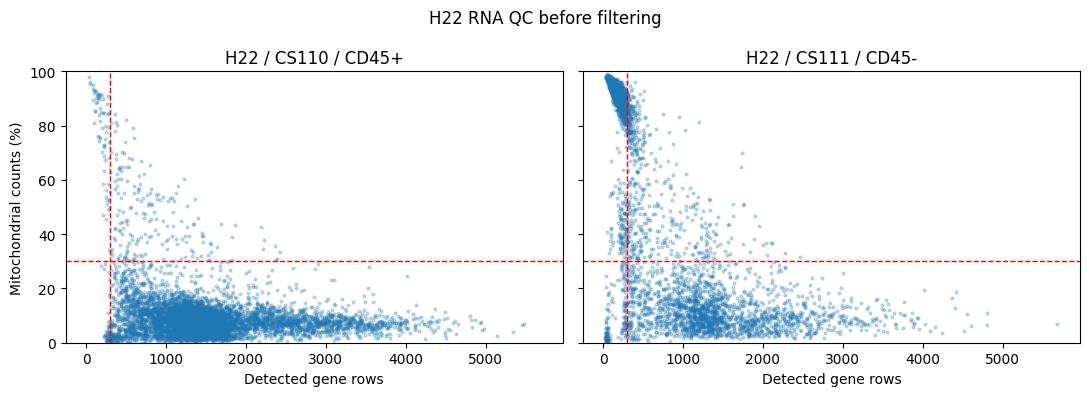

Saved: guilliams_qc/human/H22_qc_comparison.png


In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)

libraries = [
    ("GSM5764389", "H22 / CS110 / CD45+"),
    ("GSM5764390", "H22 / CS111 / CD45-"),
]

for ax, (accession, title) in zip(axes, libraries):
    qc = pd.read_csv(QC_DIR / f"{accession}_rna_qc.csv.gz")

    ax.scatter(
        qc["n_genes_by_counts"],
        qc["pct_counts_mt"],
        s=4,
        alpha=0.25,
        rasterized=True,
    )
    ax.axvline(300, color="red", linestyle="--", linewidth=1)
    ax.axhline(30, color="red", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("Detected gene rows")
    ax.set_ylim(0, 100)

axes[0].set_ylabel("Mitochondrial counts (%)")
fig.suptitle("H22 RNA QC before filtering")
fig.tight_layout()

figure_path = QC_DIR / "H22_qc_comparison.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

pd.DataFrame(comparison).to_csv(
    QC_DIR / "H22_qc_comparison.csv", index=False
)

print("Saved:", figure_path)

In [12]:
from importlib.metadata import version, PackageNotFoundError

packages = [
    "numpy",
    "pandas",
    "scipy",
    "h5py",
    "anndata",
    "scanpy",
    "scrublet",
    "celltypist",
]

for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

numpy: 2.2.6
pandas: 2.3.3
scipy: 1.15.3
h5py: 3.16.0
anndata: NOT INSTALLED
scanpy: NOT INSTALLED
scrublet: NOT INSTALLED
celltypist: NOT INSTALLED


In [13]:
%pip install "anndata==0.11.4" "zarr<3"

In [14]:
import anndata as ad

print("AnnData version:", ad.__version__)
%pip check

In [15]:
import anndata as ad

OUTPUT_DIR = PROJECT_DIR / "guilliams_qc" / "human" / "basic_qc"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

accession = "GSM5764363"
data = read_h5_rna(ARCHIVE_PATH, matrix_index[accession])

# Align saved QC metadata to the matrix barcode order.
qc = pd.read_csv(
    QC_DIR / f"{accession}_rna_qc.csv.gz",
    dtype={"barcode": str},
)
barcodes = pd.Index(data["barcodes"], name="barcode")

if qc["barcode"].duplicated().any():
    raise ValueError("Duplicate barcodes in QC metadata.")

if len(qc) != len(barcodes) or set(qc["barcode"]) != set(barcodes):
    raise ValueError("QC metadata and matrix barcodes do not match.")

qc = qc.set_index("barcode").loc[barcodes].reset_index()

np.testing.assert_array_equal(
    np.asarray(data["counts"].sum(axis=1)).ravel(),
    qc["total_counts"].to_numpy(),
)

# Apply the provisional human QC thresholds.
keep = (
    (qc["n_genes_by_counts"] >= 300)
    & (qc["n_genes_by_counts"] < 6000)
    & (qc["pct_counts_mt"] < 30)
    & np.isfinite(qc["pct_counts_mt"])
).to_numpy()

obs = qc.loc[keep].copy().set_index("cell_id")
obs["dataset"] = "guilliams"
obs["species"] = "human"

# Use stable gene IDs as the index and retain gene symbols separately.
var = pd.DataFrame(
    {"gene_name": data["gene_names"]},
    index=pd.Index(data["gene_ids"], name="gene_id"),
)

if not var.index.is_unique:
    raise ValueError("Gene IDs are not unique.")

adata = ad.AnnData(
    X=data["counts"][keep].copy(),
    obs=obs,
    var=var,
)

adata.uns["processing_stage"] = "provisional_basic_qc"
adata.uns["count_scale"] = "raw RNA counts"
adata.uns["source_file"] = matrix_index[accession]
adata.uns["condition_source"] = str(MANIFEST_PATH.relative_to(PROJECT_DIR))
adata.uns["qc_thresholds"] = {
    "min_genes_inclusive": 300,
    "max_genes_exclusive": 6000,
    "max_pct_mt_exclusive": 30.0,
}
adata.uns["doublet_detection_performed"] = False
adata.uns["cell_type_annotation_performed"] = False

output_path = OUTPUT_DIR / f"{accession}_basic_qc.h5ad"
adata.write_h5ad(output_path, compression="gzip")

# Verify the saved file.
check = ad.read_h5ad(output_path)
assert check.shape == adata.shape
assert check.obs_names.equals(adata.obs_names)
assert check.var_names.equals(adata.var_names)
assert (check.X != adata.X).nnz == 0

print("Cells before filtering:", len(qc))
print("Saved shape (cells, genes):", check.shape)
print("Read-back verification: PASS")
print("Saved:", output_path)

del data, adata, check

Cells before filtering: 9727
Saved shape (cells, genes): (9598, 32738)
Read-back verification: PASS
Saved: guilliams_qc/human/basic_qc/GSM5764363_basic_qc.h5ad


In [16]:
import gc

export_summary = []

for index, sample in enumerate(selected_samples, start=1):
    accession = sample["accession"]
    filename = matrix_index[accession]

    if filename.endswith(".h5"):
        data = read_h5_rna(ARCHIVE_PATH, filename)
    else:
        data = read_text_rna(ARCHIVE_PATH, accession)

    # Align QC metadata to the matrix barcode order.
    qc = pd.read_csv(
        QC_DIR / f"{accession}_rna_qc.csv.gz",
        dtype={"barcode": str},
    )
    barcodes = pd.Index(data["barcodes"], name="barcode")

    if qc["barcode"].duplicated().any():
        raise ValueError(f"{accession}: duplicate QC barcodes.")

    if len(qc) != len(barcodes) or set(qc["barcode"]) != set(barcodes):
        raise ValueError(f"{accession}: barcode mismatch.")

    qc = qc.set_index("barcode").loc[barcodes].reset_index()

    if not (
        qc["sample"].eq(accession).all()
        and qc["donor"].eq(sample["donor"]).all()
        and qc["condition"].eq(sample["condition"]).all()
    ):
        raise ValueError(f"{accession}: sample metadata mismatch.")

    counts = data["counts"]
    gene_names = np.asarray(data["gene_names"], dtype=str)
    totals = np.asarray(counts.sum(axis=1)).ravel()
    detected = counts.getnnz(axis=1)
    mt_mask = np.char.startswith(np.char.upper(gene_names), "MT-")

    if not mt_mask.any():
        raise ValueError(f"{accession}: no mitochondrial genes found.")

    mt_counts = np.asarray(counts[:, mt_mask].sum(axis=1)).ravel()
    pct_mt = np.divide(
        mt_counts * 100.0,
        totals,
        out=np.full(len(totals), np.nan),
        where=totals > 0,
    )

    # Verify all filtering metrics against the saved QC results.
    np.testing.assert_array_equal(totals, qc["total_counts"])
    np.testing.assert_array_equal(detected, qc["n_genes_by_counts"])
    np.testing.assert_allclose(
        pct_mt, qc["pct_counts_mt"], equal_nan=True
    )

    keep = (
        (detected >= 300)
        & (detected < 6000)
        & (pct_mt < 30)
        & np.isfinite(pct_mt)
    )

    obs = qc.loc[keep].copy().set_index("cell_id")
    obs["dataset"] = "guilliams"
    obs["species"] = "human"

    var = pd.DataFrame(
        {"gene_name": gene_names},
        index=pd.Index(data["gene_ids"], name="gene_id"),
    )

    if "original_feature_names" in data:
        var["original_feature_name"] = data["original_feature_names"]

    if not var.index.is_unique or not obs.index.is_unique:
        raise ValueError(f"{accession}: duplicate gene or cell IDs.")

    adata = ad.AnnData(
        X=counts[keep].copy(),
        obs=obs,
        var=var,
    )
    adata.uns["processing_stage"] = "provisional_basic_qc"
    adata.uns["count_scale"] = "raw RNA counts"
    adata.uns["source_file"] = filename
    adata.uns["condition_source"] = str(MANIFEST_PATH.relative_to(PROJECT_DIR))
    adata.uns["gene_id_source"] = data.get(
        "gene_id_source", "Source H5 feature IDs"
    )
    adata.uns["excluded_feature_rows"] = data["excluded_feature_rows"]
    adata.uns["qc_thresholds"] = {
        "min_genes_inclusive": 300,
        "max_genes_exclusive": 6000,
        "max_pct_mt_exclusive": 30.0,
    }
    adata.uns["doublet_detection_performed"] = False
    adata.uns["cell_type_annotation_performed"] = False

    output_path = OUTPUT_DIR / f"{accession}_basic_qc.h5ad"
    adata.write_h5ad(output_path, compression="gzip")

    check = ad.read_h5ad(output_path)
    assert check.shape == adata.shape
    assert check.obs_names.equals(adata.obs_names)
    assert check.var_names.equals(adata.var_names)
    assert (check.X != adata.X).nnz == 0

    export_summary.append({
        "sample": accession,
        "donor": sample["donor"],
        "condition": sample["condition"],
        "cells_before": len(qc),
        "cells_saved": adata.n_obs,
        "genes_saved": adata.n_vars,
        "file": str(output_path.relative_to(PROJECT_DIR)),
    })

    print(
        f"[{index}/{len(selected_samples)}] {accession}: "
        f"{adata.n_obs:,} cells saved and verified"
    )

    del data, counts, adata, check, qc, obs, var
    gc.collect()

export_table = pd.DataFrame(export_summary)
export_table.to_csv(OUTPUT_DIR / "export_summary.csv", index=False)

print("\nSamples saved:", len(export_table))
print("Total cells saved:", int(export_table["cells_saved"].sum()))
display(export_table.drop(columns="file"))

[1/20] GSM5764358: 1,192 cells saved and verified
[2/20] GSM5764361: 1,046 cells saved and verified
[3/20] GSM5764363: 9,598 cells saved and verified
[4/20] GSM5764366: 6,646 cells saved and verified
[5/20] GSM5764368: 12,218 cells saved and verified
[6/20] GSM5764370: 13,415 cells saved and verified
[7/20] GSM5764373: 7,289 cells saved and verified
[8/20] GSM5764375: 2,079 cells saved and verified
[9/20] GSM5764377: 960 cells saved and verified
[10/20] GSM5764380: 16,829 cells saved and verified
[11/20] GSM5764384: 10,995 cells saved and verified
[12/20] GSM5764385: 16,004 cells saved and verified
[13/20] GSM5764386: 4,785 cells saved and verified
[14/20] GSM5764387: 7,776 cells saved and verified
[15/20] GSM5764388: 3,870 cells saved and verified
[16/20] GSM5764389: 6,883 cells saved and verified
[17/20] GSM5764390: 1,902 cells saved and verified
[18/20] GSM5764391: 14,966 cells saved and verified
[19/20] GSM5764392: 12,065 cells saved and verified
[20/20] GSM5764393: 3,640 cells sav

,sample,donor,condition,cells_before,cells_saved,genes_saved
0,GSM5764358,H04,disease,1278,1192,32738
1,GSM5764361,H04,disease,1114,1046,32738
2,GSM5764363,H06,healthy,9727,9598,32738
3,GSM5764366,H06,healthy,6805,6646,32738
4,GSM5764368,H06,healthy,12262,12218,32738
5,GSM5764370,H06,healthy,13446,13415,32738
6,GSM5764373,H07,healthy,7650,7289,32738
7,GSM5764375,H10,healthy,2107,2079,32738
8,GSM5764377,H11,disease,997,960,32738
9,GSM5764380,H13,healthy,17155,16829,32738


In [17]:
%pip install "scanpy[scrublet]==1.11.5" "anndata==0.11.4" "zarr<3"

In [ ]:
## Doublet detection
#Run Scrublet separately for each library and review the predicted doublets before filtering.

In [18]:
import scanpy as sc
import anndata as ad
from importlib.metadata import version

print("Scanpy version:", version("scanpy"))
print("AnnData version:", ad.__version__)
print("Scrublet interface available:", callable(sc.pp.scrublet))

%pip check

Sample: GSM5764363
Input shape: (9598, 32738)
Cells tested: 9598
Predicted doublets: 2
Predicted doublet percentage: 0.02
Automatic threshold: 0.5999567469808653


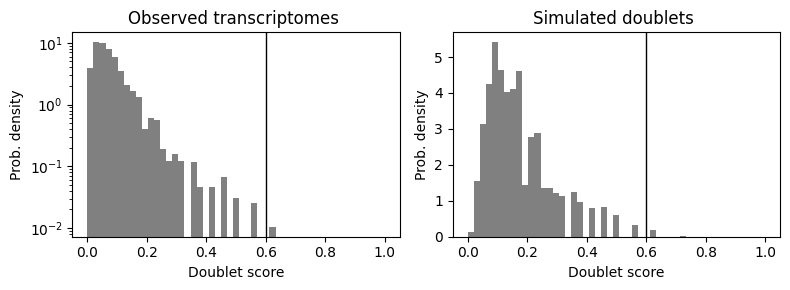

In [20]:
from pathlib import Path
import scanpy as sc

QC_ROOT = PROJECT_DIR / "guilliams_qc" / "human"
accession = "GSM5764363"

adata_test = sc.read_h5ad(
    QC_ROOT / "basic_qc" / f"{accession}_basic_qc.h5ad"
)

print("Sample:", accession)
print("Input shape:", adata_test.shape)

# Match the team's simulation ratio and use a fixed random seed.
sc.pp.scrublet(
    adata_test,
    sim_doublet_ratio=1.0,
    expected_doublet_rate=0.05,
    random_state=0,
    use_approx_neighbors=False,
)

if "predicted_doublet" not in adata_test.obs:
    raise RuntimeError("Automatic thresholding failed; review the scores.")

predicted = adata_test.obs["predicted_doublet"]

print("Cells tested:", adata_test.n_obs)
print("Predicted doublets:", int(predicted.sum()))
print("Predicted doublet percentage:", round(predicted.mean() * 100, 2))
print("Automatic threshold:", adata_test.uns["scrublet"].get("threshold"))

sc.pl.scrublet_score_distribution(adata_test)

In [21]:
import numpy as np
import pandas as pd

observed = adata_test.obs["doublet_score"].to_numpy()
simulated = np.asarray(
    adata_test.uns["scrublet"]["doublet_scores_sim"]
)
auto_threshold = float(adata_test.uns["scrublet"]["threshold"])

# Explore sensitivity; these are not approved filtering thresholds.
thresholds = sorted(set([0.15, 0.20, 0.30, 0.40, auto_threshold]))

rows = []
for threshold in thresholds:
    rows.append({
        "threshold": threshold,
        "observed_cells_above": int((observed > threshold).sum()),
        "observed_percent_above": 100 * (observed > threshold).mean(),
        "simulated_percent_above": 100 * (simulated > threshold).mean(),
    })

display(pd.DataFrame(rows).round(3))

print("Observed score quantiles:")
print(
    pd.Series(observed)
    .quantile([0.5, 0.9, 0.95, 0.99, 1.0])
    .round(4)
)

,threshold,observed_cells_above,observed_percent_above,simulated_percent_above
0,0.15,836,8.710,47.249
1,0.20,413,4.303,32.048
2,0.30,91,0.948,12.503
3,0.40,35,0.365,5.668
4,0.60,2,0.021,0.417


Observed score quantiles:
0.50    0.0628
0.90    0.1429
0.95    0.1934
0.99    0.2987
1.00    0.6299
dtype: float64


In [22]:
DOUBLET_DIR = QC_ROOT / "doublet_review"
DOUBLET_DIR.mkdir(parents=True, exist_ok=True)

# Preserve automatic predictions without treating them as final labels.
adata_test.obs["predicted_doublet_auto"] = (
    adata_test.obs.pop("predicted_doublet")
)

adata_test.uns["doublet_detection_performed"] = True
adata_test.uns["doublet_filtering_performed"] = False
adata_test.uns["doublet_review_status"] = "threshold_requires_review"
adata_test.uns["processing_stage"] = "doublet_scored_unfiltered"
adata_test.uns["doublet_review_note"] = (
    "No clear separation in the simulated score distribution. "
    "Automatic predictions are provisional; no cells were removed."
)

output_path = DOUBLET_DIR / f"{accession}_doublet_scored.h5ad"
adata_test.write_h5ad(output_path, compression="gzip")

pd.DataFrame(rows).to_csv(
    DOUBLET_DIR / f"{accession}_threshold_sensitivity.csv",
    index=False,
)

print("Cells retained:", adata_test.n_obs)
print("Review status:", adata_test.uns["doublet_review_status"])
print("Saved:", output_path)

Cells retained: 9598
Review status: threshold_requires_review
Saved: guilliams_qc/human/doublet_review/GSM5764363_doublet_scored.h5ad


In [23]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc

basic_dir = QC_ROOT / "basic_qc"
review_dir = QC_ROOT / "doublet_review"
review_dir.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(basic_dir / "export_summary.csv")
summaries = []
failures = []

for index, record in enumerate(manifest.to_dict("records"), start=1):
    sample_id = record["sample"]
    output_path = review_dir / f"{sample_id}_doublet_scored.h5ad"
    sample_data = None

    try:
        if sample_id == "GSM5764363" and output_path.exists():
            sample_data = sc.read_h5ad(output_path)
        else:
            sample_data = sc.read_h5ad(
                basic_dir / f"{sample_id}_basic_qc.h5ad"
            )

            sc.pp.scrublet(
                sample_data,
                sim_doublet_ratio=1.0,
                expected_doublet_rate=0.05,
                random_state=0,
                use_approx_neighbors=False,
            )

            if "predicted_doublet" in sample_data.obs:
                sample_data.obs["predicted_doublet_auto"] = (
                    sample_data.obs.pop("predicted_doublet")
                )

        scores = sample_data.obs["doublet_score"].to_numpy()
        simulated = np.asarray(
            sample_data.uns["scrublet"]["doublet_scores_sim"]
        )
        threshold = sample_data.uns["scrublet"].get("threshold")
        has_threshold = (
            threshold is not None and np.isfinite(threshold)
        )

        if not np.isfinite(scores).all():
            raise ValueError("Non-finite observed doublet scores.")
        if sample_data.n_obs != int(record["cells_saved"]):
            raise ValueError("Cell count differs from the basic QC export.")

        # All automatic calls require review before filtering.
        status = (
            "threshold_requires_review"
            if has_threshold
            else "automatic_threshold_failed"
        )
        sample_data.uns["doublet_detection_performed"] = True
        sample_data.uns["doublet_filtering_performed"] = False
        sample_data.uns["doublet_review_status"] = status
        sample_data.uns["processing_stage"] = "doublet_scored_unfiltered"

        # Plot observed and simulated scores on the same score scale.
        fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)
        bins = np.linspace(0, 1, 51)

        for ax, values, title in zip(
            axes,
            [scores, simulated],
            ["Observed transcriptomes", "Simulated doublets"],
        ):
            ax.hist(values, bins=bins, density=True, color="gray")
            if has_threshold:
                ax.axvline(threshold, color="red", linestyle="--")
            ax.set_title(title)
            ax.set_xlabel("Doublet score")
            ax.set_ylabel("Density")

        fig.suptitle(sample_id)
        fig.tight_layout()
        fig.savefig(
            review_dir / f"{sample_id}_score_distribution.png",
            dpi=150,
        )
        plt.close(fig)

        sample_data.write_h5ad(output_path, compression="gzip")

        summaries.append({
            "sample": sample_id,
            "donor": record["donor"],
            "condition": record["condition"],
            "cells": sample_data.n_obs,
            "automatic_threshold": threshold if has_threshold else np.nan,
            "predicted_doublets_auto": (
                int((scores > threshold).sum())
                if has_threshold else np.nan
            ),
            "predicted_percent_auto": (
                100 * (scores > threshold).mean()
                if has_threshold else np.nan
            ),
            "simulated_percent_above_threshold": (
                100 * (simulated > threshold).mean()
                if has_threshold else np.nan
            ),
            "review_status": status,
        })

        print(f"[{index}/{len(manifest)}] {sample_id}: scored and saved")

    except Exception as error:
        failures.append({
            "sample": sample_id,
            "error": f"{type(error).__name__}: {error}",
        })
        print(f"[{index}/{len(manifest)}] {sample_id}: FAILED — {error}")

    finally:
        plt.close("all")
        del sample_data
        gc.collect()

    # Save progress after every sample.
    pd.DataFrame(summaries).to_csv(
        review_dir / "doublet_summary.csv", index=False
    )
    pd.DataFrame(failures, columns=["sample", "error"]).to_csv(
        review_dir / "doublet_failures.csv", index=False
    )

doublet_summary = pd.DataFrame(summaries)

print("\nSamples completed:", len(summaries))
print("Samples failed:", len(failures))
print("No cells were removed.")
display(doublet_summary.round(3))

[1/20] GSM5764358: scored and saved
[2/20] GSM5764361: scored and saved
[3/20] GSM5764363: scored and saved
[4/20] GSM5764366: scored and saved
[5/20] GSM5764368: scored and saved
[6/20] GSM5764370: scored and saved
[7/20] GSM5764373: scored and saved
[8/20] GSM5764375: scored and saved
[9/20] GSM5764377: scored and saved
[10/20] GSM5764380: scored and saved
[11/20] GSM5764384: scored and saved
[12/20] GSM5764385: scored and saved
[13/20] GSM5764386: scored and saved
[14/20] GSM5764387: scored and saved
[15/20] GSM5764388: scored and saved
[16/20] GSM5764389: scored and saved
[17/20] GSM5764390: scored and saved
[18/20] GSM5764391: scored and saved
[19/20] GSM5764392: scored and saved
[20/20] GSM5764393: scored and saved

Samples completed: 20
Samples failed: 0
No cells were removed.


,sample,donor,condition,cells,automatic_threshold,predicted_doublets_auto,predicted_percent_auto,simulated_percent_above_threshold,review_status
0,GSM5764358,H04,disease,1192,0.337,4,0.336,5.537,threshold_requires_review
1,GSM5764361,H04,disease,1046,0.324,9,0.860,4.589,threshold_requires_review
2,GSM5764363,H06,healthy,9598,0.600,2,0.021,0.417,threshold_requires_review
3,GSM5764366,H06,healthy,6646,0.566,3,0.045,0.662,threshold_requires_review
4,GSM5764368,H06,healthy,12218,0.506,1,0.008,0.188,threshold_requires_review
5,GSM5764370,H06,healthy,13415,0.485,0,0.000,0.171,threshold_requires_review
6,GSM5764373,H07,healthy,7289,0.304,116,1.591,26.945,threshold_requires_review
7,GSM5764375,H10,healthy,2079,0.416,6,0.289,11.496,threshold_requires_review
8,GSM5764377,H11,disease,960,0.303,5,0.521,15.833,threshold_requires_review
9,GSM5764380,H13,healthy,16829,0.182,1311,7.790,44.067,threshold_requires_review


Sample: GSM5764363


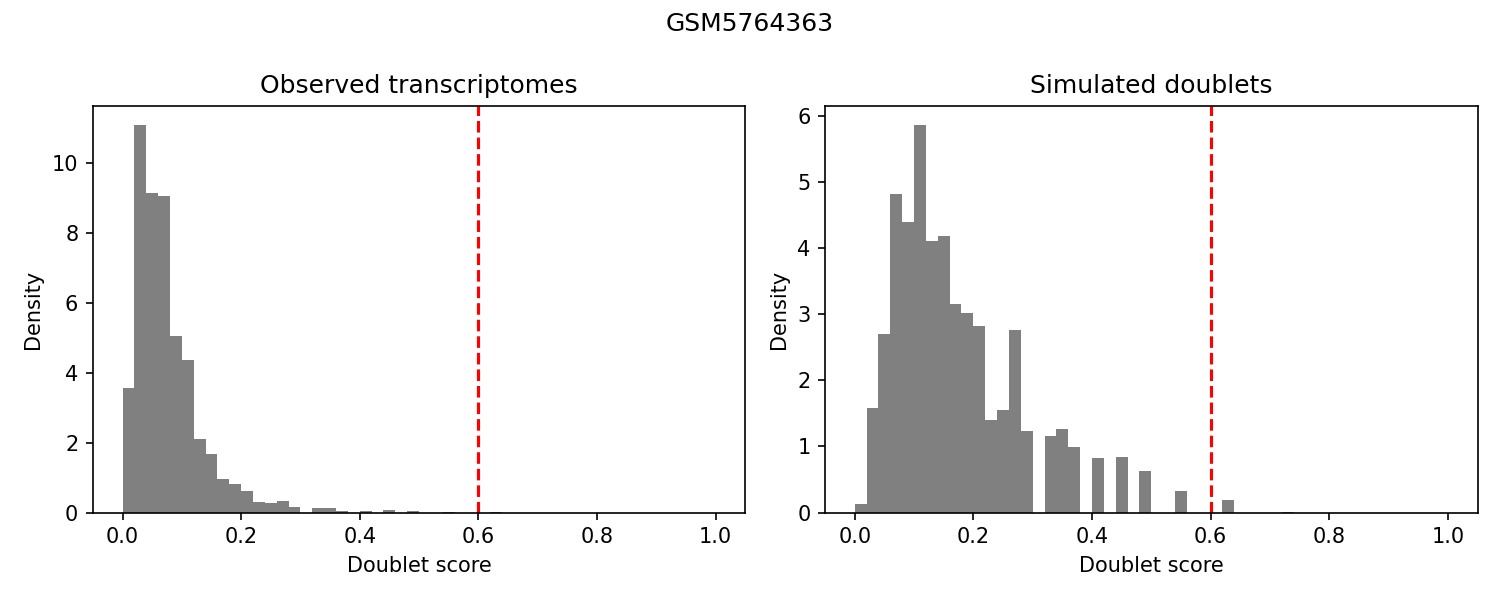

Sample: GSM5764384


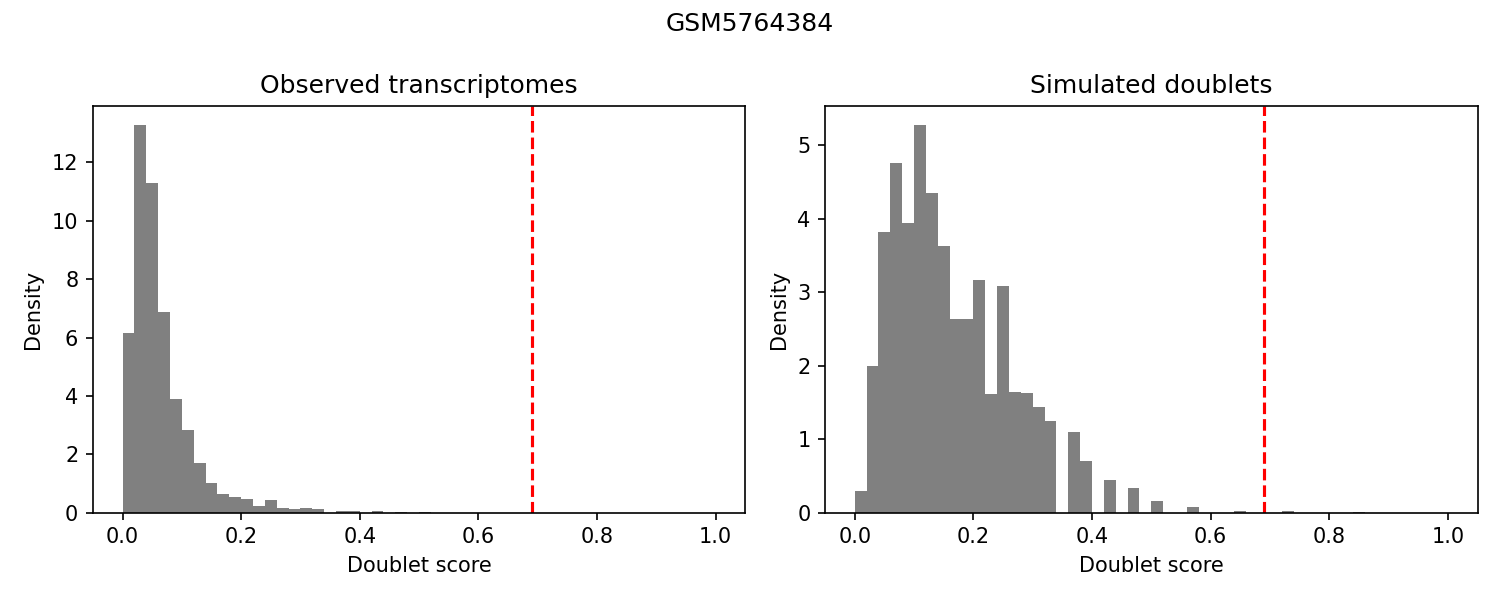

Sample: GSM5764380


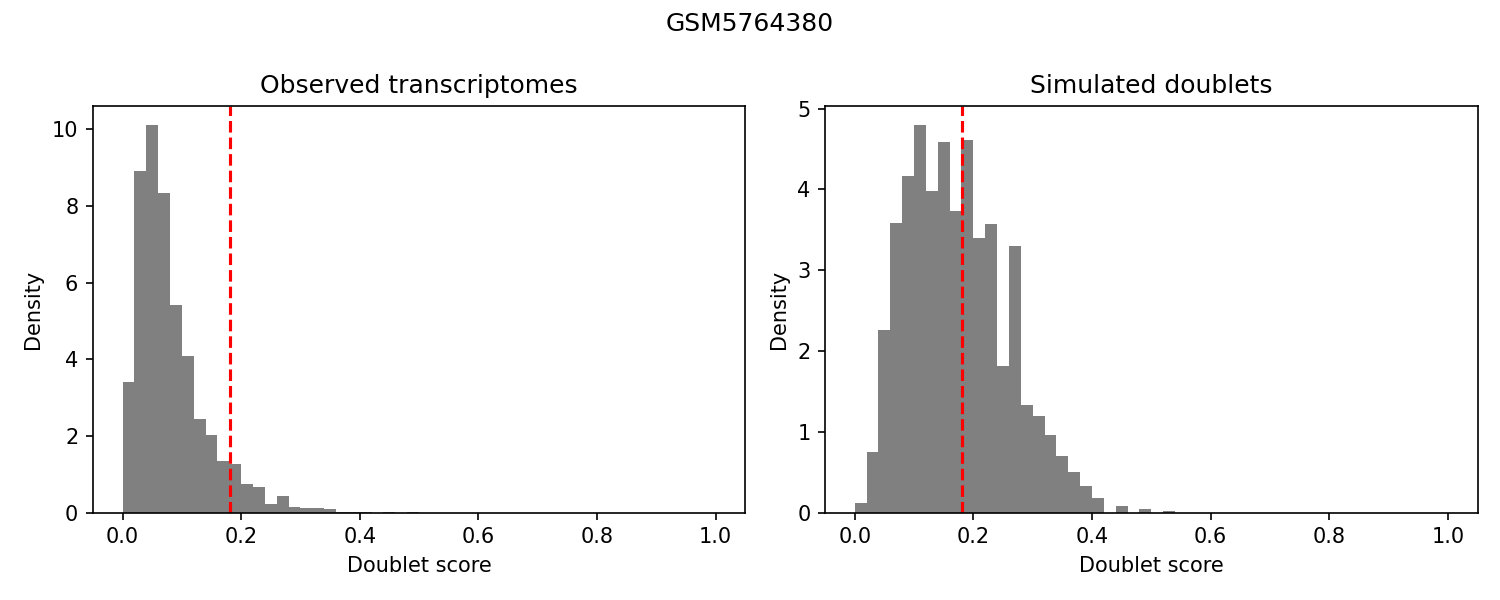

Sample: GSM5764373


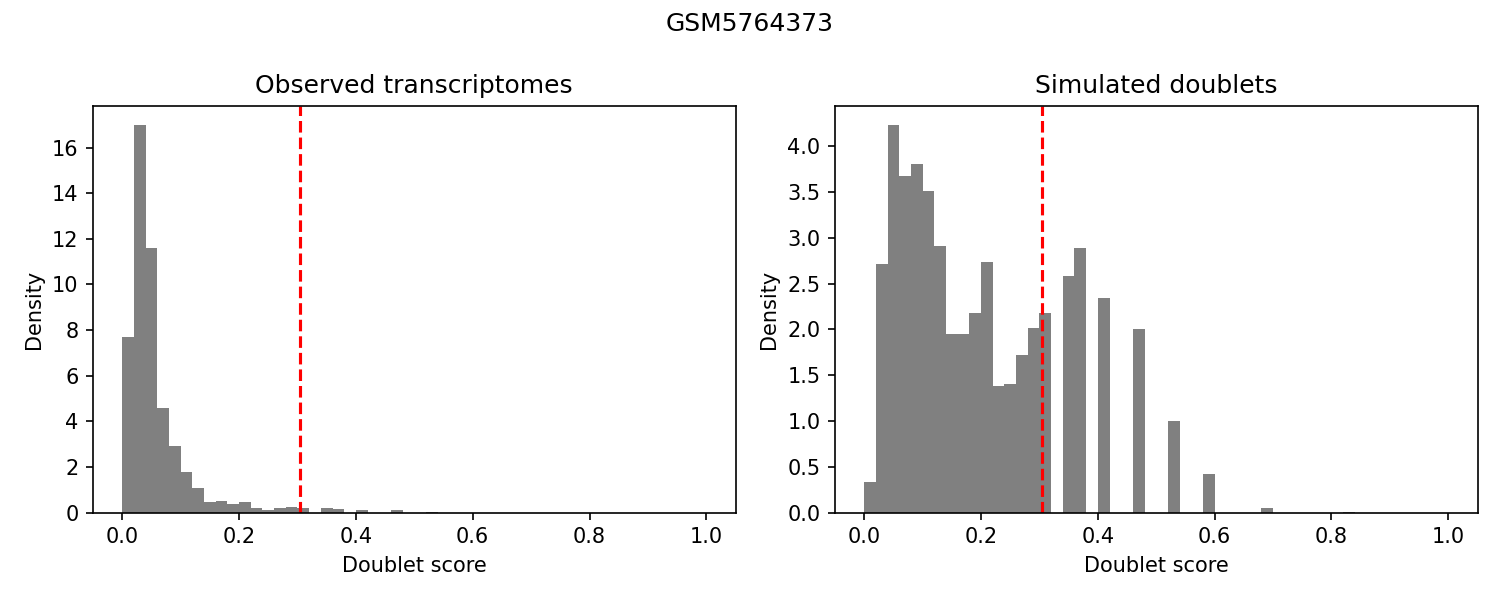

In [24]:
from IPython.display import display, Image

review_samples = [
    "GSM5764363",  # Very few predicted doublets
    "GSM5764384",  # No predicted doublets
    "GSM5764380",  # Highest predicted percentage
    "GSM5764373",  # Intermediate predicted percentage
]

for sample_id in review_samples:
    figure_path = (
        QC_ROOT / "doublet_review"
        / f"{sample_id}_score_distribution.png"
    )
    print("Sample:", sample_id)
    display(Image(filename=str(figure_path), width=900))